In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import time
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None) # Show all columns
pd.set_option('display.width', 1000) # Adjust display width

In [2]:
df = pd.read_csv('CIC-BCCC-NRC-TabularIoTAttacks-2024-balanced_dataset.csv')

In [3]:
df.head()

,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Attack_type,Attack
0,6,4581649,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.654786,2290824.5,2.905022e+06,4344985.0,236664.0,4344985.0,4344985.0,0.0,4344985.0,4344985.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,20,0.436524,0.218262,0.0,0.0,0.0,0.0,0.0,0,0,1,0,2,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2,0,1,0,512,0,0,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,DDoS,ACK Flood
1,6,300972,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.645136,300972.0,0.000000e+00,300972.0,300972.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,20,20,3.322568,3.322568,0.0,0.0,0.0,0.0,0.0,0,0,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,512,0,0,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,DDoS,ACK Flood
2,6,7462882,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.401989,3731441.0,4.894292e+06,7192228.0,270654.0,7192228.0,7192228.0,0.0,7192228.0,7192228.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,20,0.267993,0.133996,0.0,0.0,0.0,0.0,0.0,0,0,1,0,2,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2,0,1,0,512,0,0,20,0.0,0.0,0.0,0.0,7192228.0,0.0,7192228.0,7192228.0,1,DDoS,ACK Flood
3,6,304278,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.572937,304278.0,0.000000e+00,304278.0,304278.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,20,20,3.286468,3.286468,0.0,0.0,0.0,0.0,0.0,0,0,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,512,0,0,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,DDoS,ACK Flood
4,6,9177775,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.326877,4588887.5,6.205263e+06,8976671.0,201104.0,8976671.0,8976671.0,0.0,8976671.0,8976671.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,20,0.217918,0.108959,0.0,0.0,0.0,0.0,0.0,0,0,1,0,2,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2,0,1,0,512,0,0,20,0.0,0.0,0.0,0.0,8976671.0,0.0,8976671.0,8976671.0,1,DDoS,ACK Flood


In [4]:
df.duplicated().sum()

0

In [5]:
df.isnull().any().any()

False

In [6]:
df.isnull().sum()

Protocol                      0
Flow Duration                 0
Total Fwd Packet              0
Total Bwd packets             0
Total Length of Fwd Packet    0
Total Length of Bwd Packet    0
Fwd Packet Length Max         0
Fwd Packet Length Min         0
Fwd Packet Length Mean        0
Fwd Packet Length Std         0
Bwd Packet Length Max         0
Bwd Packet Length Min         0
Bwd Packet Length Mean        0
Bwd Packet Length Std         0
Flow Bytes/s                  0
Flow Packets/s                0
Flow IAT Mean                 0
Flow IAT Std                  0
Flow IAT Max                  0
Flow IAT Min                  0
Fwd IAT Total                 0
Fwd IAT Mean                  0
Fwd IAT Std                   0
Fwd IAT Max                   0
Fwd IAT Min                   0
Bwd IAT Total                 0
Bwd IAT Mean                  0
Bwd IAT Std                   0
Bwd IAT Max                   0
Bwd IAT Min                   0
Fwd PSH Flags                 0
Bwd PSH 

In [7]:
df.shape

(1076588, 80)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1076588 entries, 0 to 1076587
Data columns (total 80 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   Protocol                    1076588 non-null  int64  
 1   Flow Duration               1076588 non-null  int64  
 2   Total Fwd Packet            1076588 non-null  int64  
 3   Total Bwd packets           1076588 non-null  int64  
 4   Total Length of Fwd Packet  1076588 non-null  float64
 5   Total Length of Bwd Packet  1076588 non-null  float64
 6   Fwd Packet Length Max       1076588 non-null  float64
 7   Fwd Packet Length Min       1076588 non-null  float64
 8   Fwd Packet Length Mean      1076588 non-null  float64
 9   Fwd Packet Length Std       1076588 non-null  float64
 10  Bwd Packet Length Max       1076588 non-null  float64
 11  Bwd Packet Length Min       1076588 non-null  float64
 12  Bwd Packet Length Mean      1076588 non-null  float64
 1

In [7]:
df = df.drop(['Attack_type', 'Label'], axis=1)

In [8]:
df.isnull().sum()

Protocol                      0
Flow Duration                 0
Total Fwd Packet              0
Total Bwd packets             0
Total Length of Fwd Packet    0
Total Length of Bwd Packet    0
Fwd Packet Length Max         0
Fwd Packet Length Min         0
Fwd Packet Length Mean        0
Fwd Packet Length Std         0
Bwd Packet Length Max         0
Bwd Packet Length Min         0
Bwd Packet Length Mean        0
Bwd Packet Length Std         0
Flow Bytes/s                  0
Flow Packets/s                0
Flow IAT Mean                 0
Flow IAT Std                  0
Flow IAT Max                  0
Flow IAT Min                  0
Fwd IAT Total                 0
Fwd IAT Mean                  0
Fwd IAT Std                   0
Fwd IAT Max                   0
Fwd IAT Min                   0
Bwd IAT Total                 0
Bwd IAT Mean                  0
Bwd IAT Std                   0
Bwd IAT Max                   0
Bwd IAT Min                   0
Fwd PSH Flags                 0
Bwd PSH 

In [9]:
df['Attack'].unique()

array(['ACK Flood', 'Backdoor', 'Benign Traffic',
       'DDoS ACK Fragmentation', 'DDoS HTTP Flood', 'DDoS ICMP Flood',
       'DDoS ICMP Fragmentation', 'DDoS PSHACK Flood',
       'DDoS RSTFIN Flood', 'DDoS UDP Flood', 'Dictionary Brute Force',
       'DoS DNS Flood', 'DoS ICMP Flood', 'DoS SYN Flood',
       'DoS TCP Flood', 'DoS UDP Flood', 'MITM', 'MITM ARP Spoofing',
       'MQTT Brute Force', 'MQTT DDoS Publish Flood',
       'MQTT DoS Connect Flood', 'MQTT Malformed', 'Mirai ACK Flood',
       'Mirai HTTP Flood', 'Mirai Host Brute Force', 'Mirai UDP Plain',
       'Password Attack', 'Ransomware', 'Recon OS Scan',
       'Recon Ping Sweep', 'Recon Port Scan', 'Recon Vulnerability Scan',
       'SQL Injection', 'SYN Flood', 'Scan Aggressive', 'Scan Host Port',
       'Scan Port OS', 'Scan UDP Attack', 'Sparta SSH Brute Force',
       'Uploading Attack', 'Vulnerability Scanner', 'XSS'], dtype=object)

In [10]:
df = df.drop(['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Bytes/Bulk Avg', 
              'Fwd Packet/Bulk Avg', 'Fwd Bulk Rate Avg', 'URG Flag Count', 'CWR Flag Count', 'Fwd URG Flags'], axis=1)

<h2>Outliers</h2>

In [11]:
df2 = df.copy()

In [12]:
df2['Attack'].unique()

array(['ACK Flood', 'Backdoor', 'Benign Traffic',
       'DDoS ACK Fragmentation', 'DDoS HTTP Flood', 'DDoS ICMP Flood',
       'DDoS ICMP Fragmentation', 'DDoS PSHACK Flood',
       'DDoS RSTFIN Flood', 'DDoS UDP Flood', 'Dictionary Brute Force',
       'DoS DNS Flood', 'DoS ICMP Flood', 'DoS SYN Flood',
       'DoS TCP Flood', 'DoS UDP Flood', 'MITM', 'MITM ARP Spoofing',
       'MQTT Brute Force', 'MQTT DDoS Publish Flood',
       'MQTT DoS Connect Flood', 'MQTT Malformed', 'Mirai ACK Flood',
       'Mirai HTTP Flood', 'Mirai Host Brute Force', 'Mirai UDP Plain',
       'Password Attack', 'Ransomware', 'Recon OS Scan',
       'Recon Ping Sweep', 'Recon Port Scan', 'Recon Vulnerability Scan',
       'SQL Injection', 'SYN Flood', 'Scan Aggressive', 'Scan Host Port',
       'Scan Port OS', 'Scan UDP Attack', 'Sparta SSH Brute Force',
       'Uploading Attack', 'Vulnerability Scanner', 'XSS'], dtype=object)

In [13]:
attack_mapping = {
    'ACK Flood' : 1, 
'Backdoor' : 2, 
'Benign Traffic' : 0,
'DDoS ACK Fragmentation' : 3, 
'DDoS HTTP Flood' : 4, 
'DDoS ICMP Flood' : 5,
'DDoS ICMP Fragmentation' : 6, 
'DDoS PSHACK Flood' : 7,
'DDoS RSTFIN Flood' : 8, 
'DDoS UDP Flood' : 9, 
'Dictionary Brute Force' : 10,
'DoS DNS Flood' : 11, 
'DoS ICMP Flood' : 12, 
'DoS SYN Flood' : 13,
 'DoS TCP Flood' : 14, 
'DoS UDP Flood' : 15, 
'MITM' : 16, 
'MITM ARP Spoofing' : 17,
'MQTT Brute Force' : 18, 
'MQTT DDoS Publish Flood' : 19,
'MQTT DoS Connect Flood' : 20, 
'MQTT Malformed' : 21, 
'Mirai ACK Flood' : 22,
'Mirai HTTP Flood' : 23, 
'Mirai Host Brute Force' : 24, 
'Mirai UDP Plain' : 25,
'Password Attack' : 26, 
'Ransomware' : 27, 
'Recon OS Scan' : 28,
'Recon Ping Sweep' : 29 , 
'Recon Port Scan' : 30, 
'Recon Vulnerability Scan' : 31,
'SQL Injection' : 32, 
'SYN Flood' : 33, 
'Scan Aggressive' : 34, 
'Scan Host Port' : 35,
'Scan Port OS' : 36, 
'Scan UDP Attack' : 37, 
'Sparta SSH Brute Force' : 38,
'Uploading Attack' : 39, 
'Vulnerability Scanner' : 40, 
'XSS' : 41
}

df2['Attack'] = df2['Attack'].apply(lambda x: attack_mapping[x])

In [14]:
df2['Attack'].unique()

array([ 1,  2,  0,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41], dtype=int64)

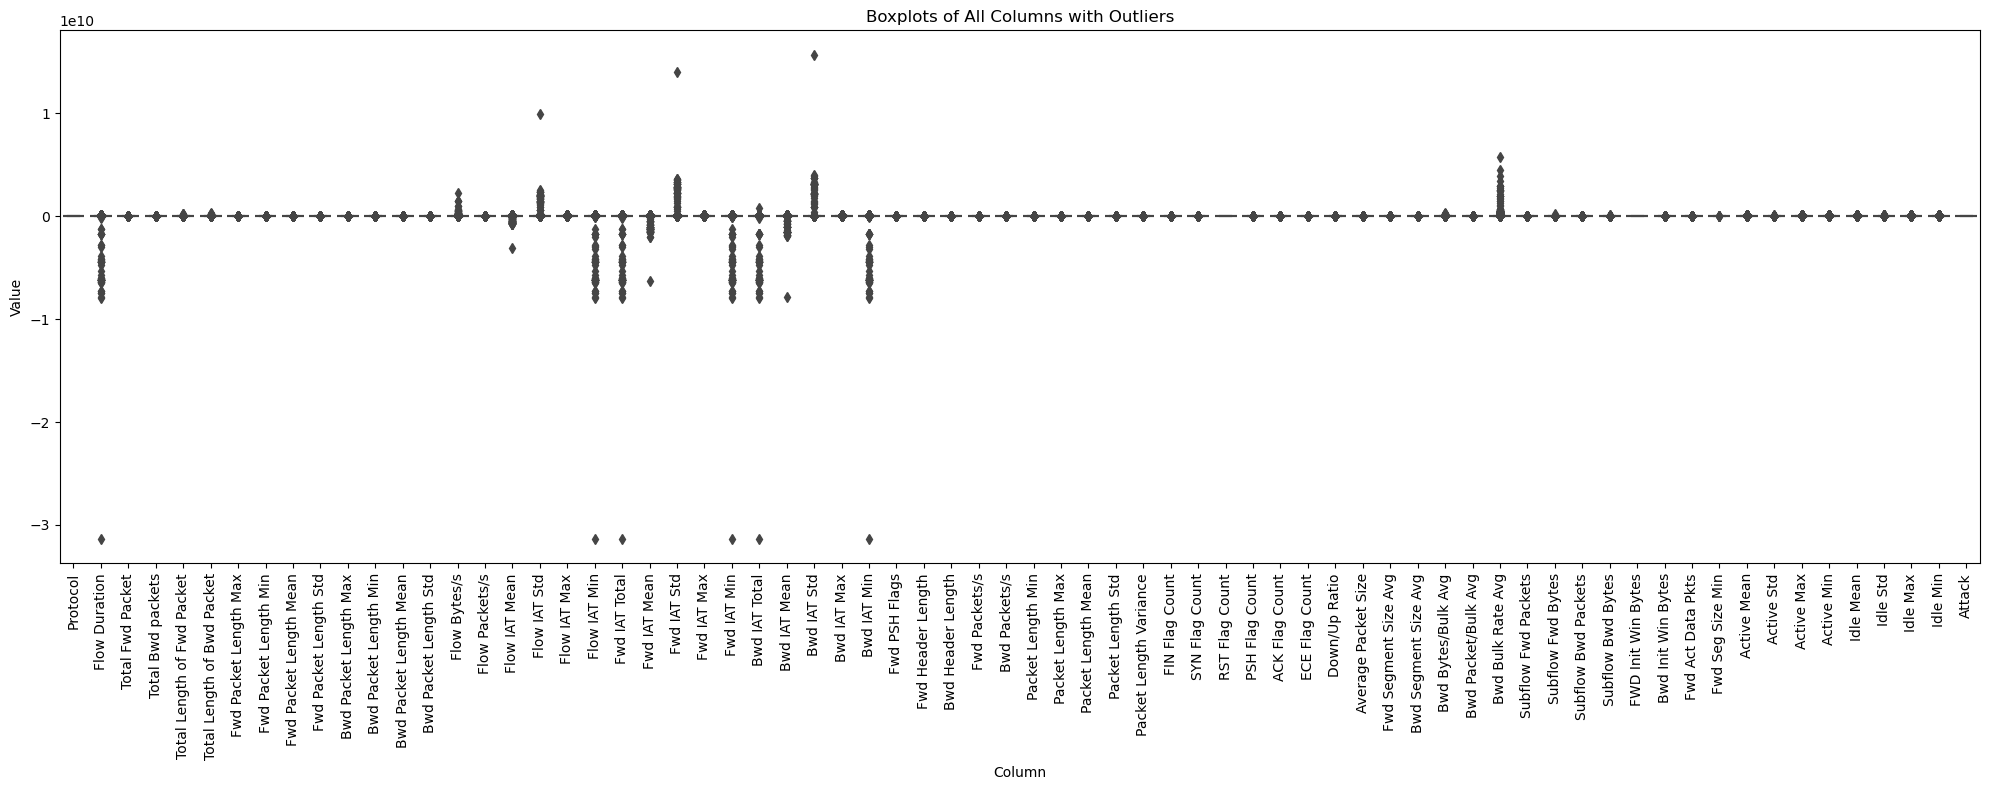

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

In [16]:
outliers_per_column = {}
for col in df2.select_dtypes(include=np.number).columns:
    Q1 = df2[col].quantile(0.25)
    Q3 = df2[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]
    outliers_per_column[col] = len(outliers)

In [17]:
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 187276,
 'Total Fwd Packet': 101474,
 'Total Bwd packets': 82392,
 'Total Length of Fwd Packet': 218708,
 'Total Length of Bwd Packet': 235451,
 'Fwd Packet Length Max': 211078,
 'Fwd Packet Length Min': 69940,
 'Fwd Packet Length Mean': 215848,
 'Fwd Packet Length Std': 186950,
 'Bwd Packet Length Max': 234713,
 'Bwd Packet Length Min': 40220,
 'Bwd Packet Length Mean': 236526,
 'Bwd Packet Length Std': 201638,
 'Flow Bytes/s': 247746,
 'Flow Packets/s': 141990,
 'Flow IAT Mean': 180270,
 'Flow IAT Std': 212439,
 'Flow IAT Max': 160066,
 'Flow IAT Min': 226362,
 'Fwd IAT Total': 195049,
 'Fwd IAT Mean': 178881,
 'Fwd IAT Std': 225292,
 'Fwd IAT Max': 162928,
 'Fwd IAT Min': 211025,
 'Bwd IAT Total': 236209,
 'Bwd IAT Mean': 221740,
 'Bwd IAT Std': 241932,
 'Bwd IAT Max': 222593,
 'Bwd IAT Min': 239503,
 'Fwd PSH Flags': 95361,
 'Fwd Header Length': 91161,
 'Bwd Header Length': 71362,
 'Fwd Packets/s': 134854,
 'Bwd Packets/s': 176220,
 'Packet Length 

In [18]:
outliers_per_column.pop("Attack")
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 187276,
 'Total Fwd Packet': 101474,
 'Total Bwd packets': 82392,
 'Total Length of Fwd Packet': 218708,
 'Total Length of Bwd Packet': 235451,
 'Fwd Packet Length Max': 211078,
 'Fwd Packet Length Min': 69940,
 'Fwd Packet Length Mean': 215848,
 'Fwd Packet Length Std': 186950,
 'Bwd Packet Length Max': 234713,
 'Bwd Packet Length Min': 40220,
 'Bwd Packet Length Mean': 236526,
 'Bwd Packet Length Std': 201638,
 'Flow Bytes/s': 247746,
 'Flow Packets/s': 141990,
 'Flow IAT Mean': 180270,
 'Flow IAT Std': 212439,
 'Flow IAT Max': 160066,
 'Flow IAT Min': 226362,
 'Fwd IAT Total': 195049,
 'Fwd IAT Mean': 178881,
 'Fwd IAT Std': 225292,
 'Fwd IAT Max': 162928,
 'Fwd IAT Min': 211025,
 'Bwd IAT Total': 236209,
 'Bwd IAT Mean': 221740,
 'Bwd IAT Std': 241932,
 'Bwd IAT Max': 222593,
 'Bwd IAT Min': 239503,
 'Fwd PSH Flags': 95361,
 'Fwd Header Length': 91161,
 'Bwd Header Length': 71362,
 'Fwd Packets/s': 134854,
 'Bwd Packets/s': 176220,
 'Packet Length 

In [19]:
#Cap Outliers (Winsorize / Clipping Approach)
def cap_outliers_iqr(df2, column):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df2[column] = np.where(df2[column] < lower, lower,
                 np.where(df2[column] > upper, upper, df2[column]))
    return df2

# Apply to columns with outliers
for col, count in outliers_per_column.items():
    if count > 0:
        df2 = cap_outliers_iqr(df2, col)

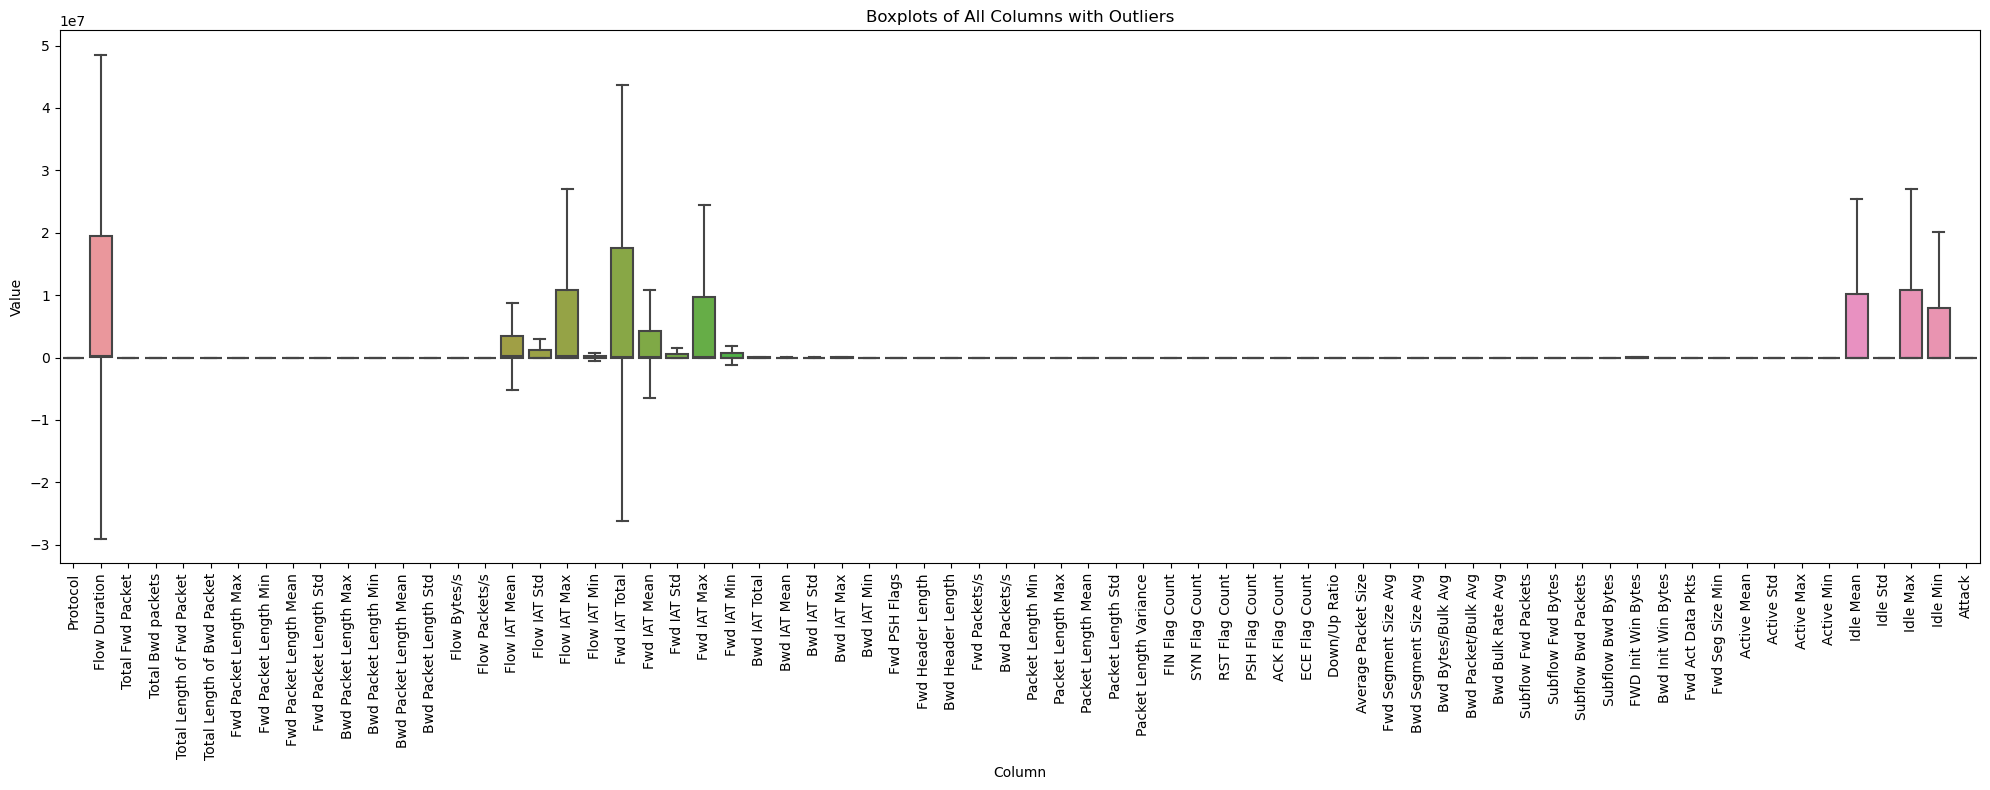

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

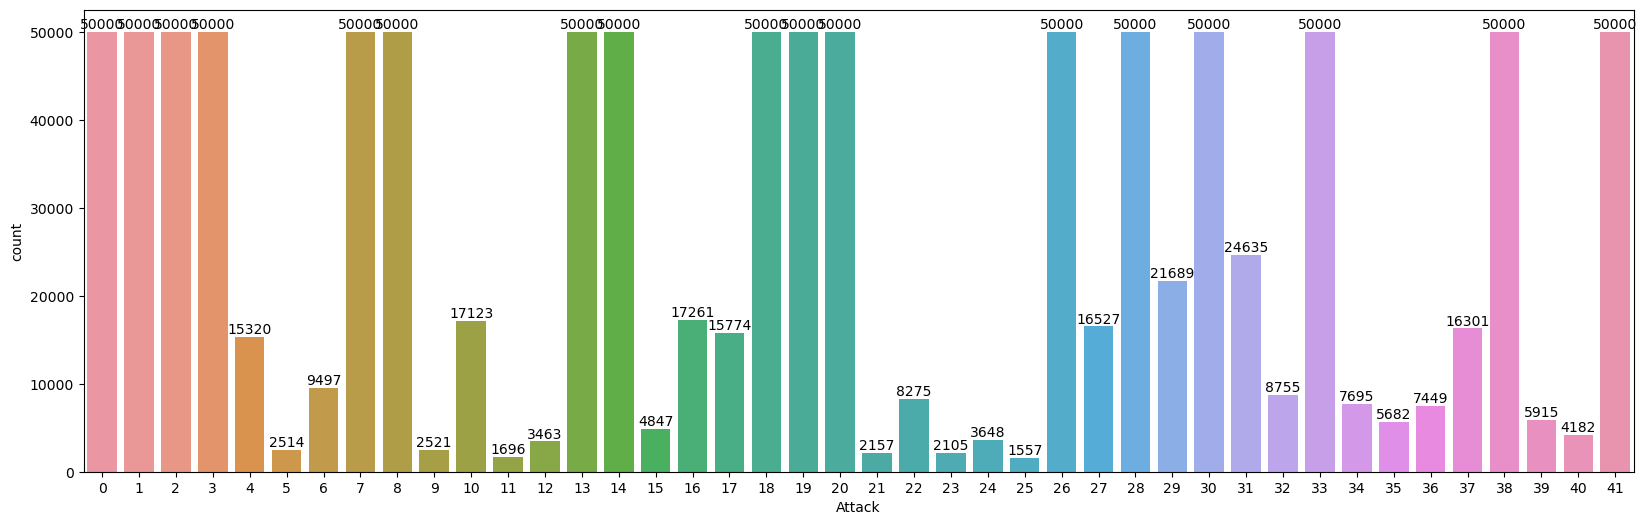

In [29]:
plt.figure(figsize=(20,6))
ax = sns.countplot(x='Attack',data=df2)
for i in ax.containers:
    ax.bar_label(i,)

In [30]:
df2.shape

(1076588, 70)

In [31]:
df2.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
      

In [21]:
columns = ['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
       'Bwd Bytes/Bulk Avg', 'Bwd Packet/Bulk Avg', 'Bwd Bulk Rate Avg', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'FWD Init Win Bytes', 'Bwd Init Win Bytes', 'Fwd Act Data Pkts', 'Fwd Seg Size Min', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']

In [29]:
!pip install --upgrade scikit-learn
!pip install --upgrade imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB 217.9 kB/s eta 0:00:41
   ---------------------------------------- 0.1/8.9 MB 656.4 kB/s eta 0:00:14
   - -------------------------------------- 0.2/8.9 MB 1.5 MB/s eta 0:00:06
   - -------------------------------------- 0.4/8.9 MB 2.0 MB/s eta 0:00:05
   --- ------------------------------------ 0.7/8.9 MB 3.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/8.9 MB 4.6 MB/s eta 0:00:02
   -------- ------------------------------- 1.8/8.9 MB 5.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.3/8.9 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.3/8.9 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.4/8.9 MB 5.2 MB/s eta 0:00:02
   -------------- --

  You can safely remove it manually.


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/240.0 kB ? eta -:--:--
   - -------------------------------------- 10.2/240.0 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/240.0 kB 262.6 kB/s eta 0:00:01
   --------- ----------------------------- 61.4/240.0 kB 465.5 kB/s eta 0:00:01
   ---------------------------------- ----- 204.8/240.0 kB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 240.0/240.0 kB 1.2 MB/s eta 0:00:00


In [22]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Split features/labels
X = df2.drop(columns=['Attack'])
y = df2['Attack']

# Train-test split first (important to avoid leakage!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Apply SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_bal.value_counts())

Attack
3     40000
33    40000
28    40000
18    40000
30    40000
26    40000
19    40000
20    40000
0     40000
38    40000
7     40000
8     40000
13    40000
41    40000
1     40000
14    40000
2     40000
31    19708
29    17351
16    13809
10    13698
27    13221
37    13041
17    12619
4     12256
6      7597
32     7004
22     6620
34     6156
36     5959
39     4732
35     4546
15     3878
40     3346
24     2918
12     2770
9      2017
5      2011
21     1726
23     1684
11     1357
25     1246
Name: count, dtype: int64
Attack
16    40000
31    40000
40    40000
28    40000
26    40000
6     40000
10    40000
24    40000
36    40000
33    40000
35    40000
2     40000
23    40000
17    40000
22    40000
27    40000
25    40000
11    40000
9     40000
5     40000
34    40000
3     40000
7     40000
39    40000
14    40000
1     40000
41    40000
13    40000
8     40000
29    40000
37    40000
38    40000
12    40000
0     40000
20    40000
19    40000
15    40000
30    40000


<h2>ML Models</h2>

In [31]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [33]:
pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [34]:
pip install catboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



🔹 Training Logistic Regression...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Logistic Regression Performance:
  Accuracy:  0.7911
  Precision: 0.7826
  Recall:    0.7911
  F1-score:  0.7811


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize


Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.83      0.87     10000
           1       0.98      0.99      0.99     10000
           2       0.58      0.70      0.63     10000
           3       0.97      0.97      0.97     10000
           4       0.86      0.78      0.82      3064
           5       0.22      0.21      0.21       503
           6       0.62      0.53      0.57      1900
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       0.18      0.10      0.13       504
          10       0.34      0.53      0.41      3425
          11       0.00      0.00      0.00       339
          12       0.18      0.06      0.09       693
          13       0.96      0.97      0.96     10000
          14       0.99      0.97      0.98     10000
          15       0.17      0.08      0.11       969
          16       0.68      0.58      0.63      3452
  

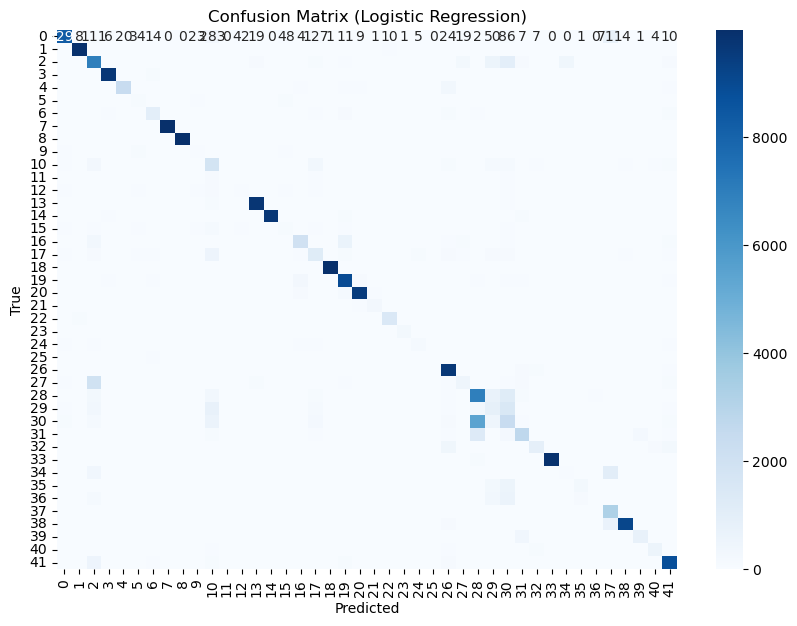


🔹 Training Random Forest...
Random Forest Performance:
  Accuracy:  0.8524
  Precision: 0.8528
  Recall:    0.8524
  F1-score:  0.8517

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.89      0.91     10000
           1       1.00      1.00      1.00     10000
           2       0.83      0.87      0.85     10000
           3       0.99      0.98      0.98     10000
           4       0.96      0.96      0.96      3064
           5       0.50      0.53      0.51       503
           6       0.78      0.86      0.82      1900
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       0.48      0.45      0.47       504
          10       0.60      0.68      0.64      3425
          11       0.36      0.22      0.28       339
          12       0.44      0.36      0.40       693
          13       0.99      0.98      0.98     10000
          14       0.99     

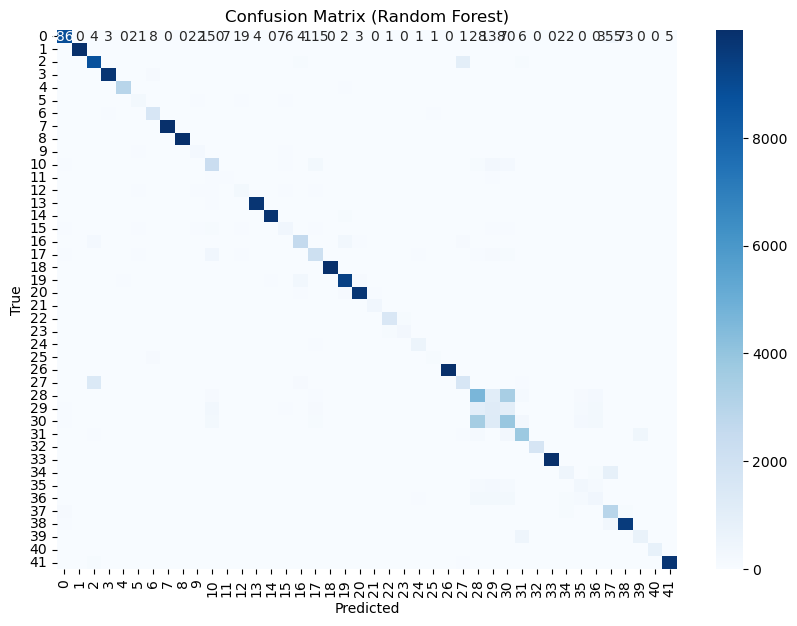


🔹 Training XGBoost...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [07:35:33] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Performance:
  Accuracy:  0.8754
  Precision: 0.8814
  Recall:    0.8754
  F1-score:  0.8736

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.88      0.92     10000
           1       1.00      1.00      1.00     10000
           2       0.83      0.90      0.86     10000
           3       0.99      0.98      0.98     10000
           4       0.98      0.96      0.97      3064
           5       0.40      0.50      0.44       503
           6       0.80      0.87      0.83      1900
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       0.39      0.41      0.40       504
          10       0.50      0.81      0.62      3425
          11       0.63      0.18      0.28       339
          12       0.41      0.24      0.30       693
          13       1.00      0.98      0.99     10000
          14       1.00      0.99      0.99     10000
         

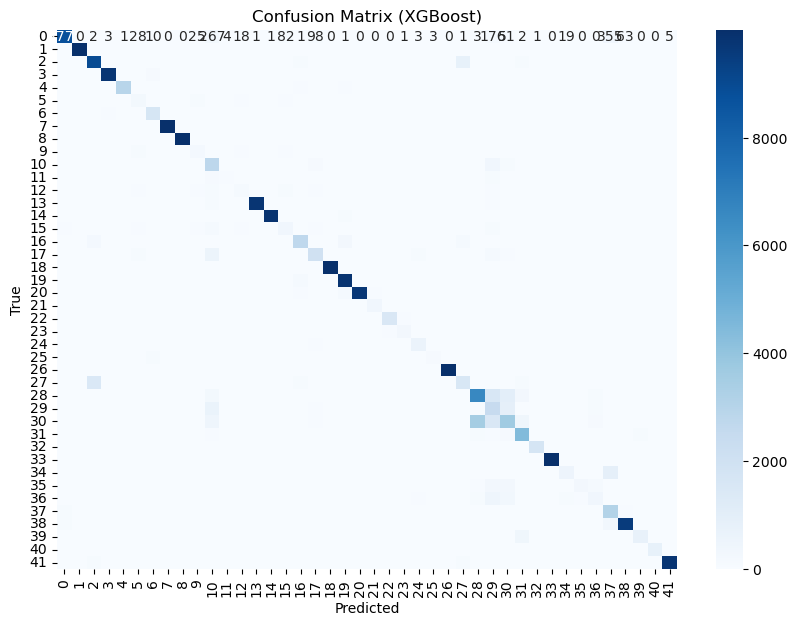


🔹 Training KNN...
KNN Performance:
  Accuracy:  0.8537
  Precision: 0.8526
  Recall:    0.8537
  F1-score:  0.8516

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.88      0.89     10000
           1       0.98      0.99      0.99     10000
           2       0.81      0.87      0.84     10000
           3       0.98      0.98      0.98     10000
           4       0.94      0.95      0.95      3064
           5       0.35      0.45      0.40       503
           6       0.76      0.79      0.78      1900
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       0.31      0.29      0.30       504
          10       0.52      0.72      0.61      3425
          11       0.28      0.17      0.21       339
          12       0.28      0.21      0.24       693
          13       0.99      0.98      0.98     10000
          14       1.00      0.99      0.99     

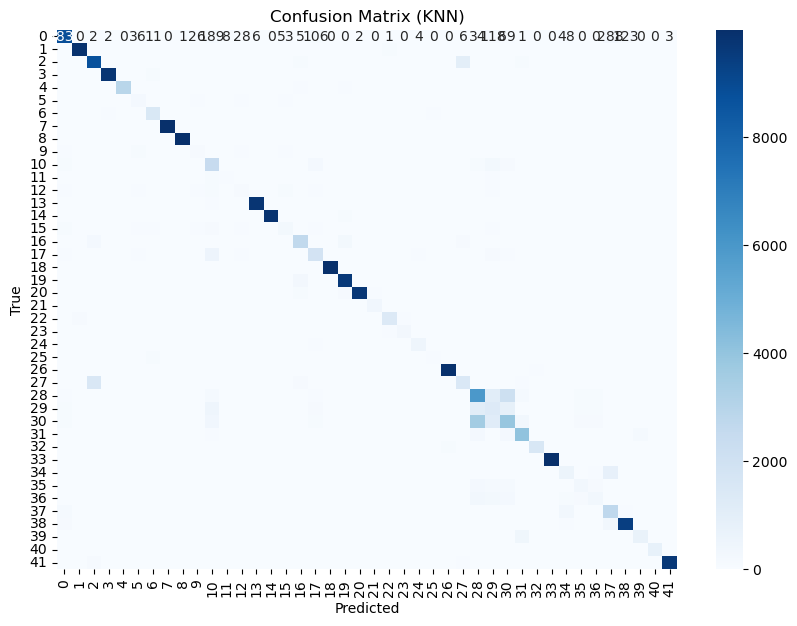


🔹 Training Naive Bayes...
Naive Bayes Performance:
  Accuracy:  0.4878
  Precision: 0.4658
  Recall:    0.4878
  F1-score:  0.4346

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00     10000
           1       0.43      0.62      0.51     10000
           2       0.00      0.00      0.00     10000
           3       0.99      0.65      0.78     10000
           4       0.71      0.56      0.62      3064
           5       0.10      0.62      0.18       503
           6       0.17      0.04      0.07      1900
           7       0.76      0.96      0.85     10000
           8       1.00      1.00      1.00     10000
           9       0.01      0.07      0.02       504
          10       0.07      0.00      0.00      3425
          11       0.00      0.00      0.00       339
          12       0.01      0.01      0.01       693
          13       0.66      0.94      0.77     10000
          14       0.00      0.0

C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

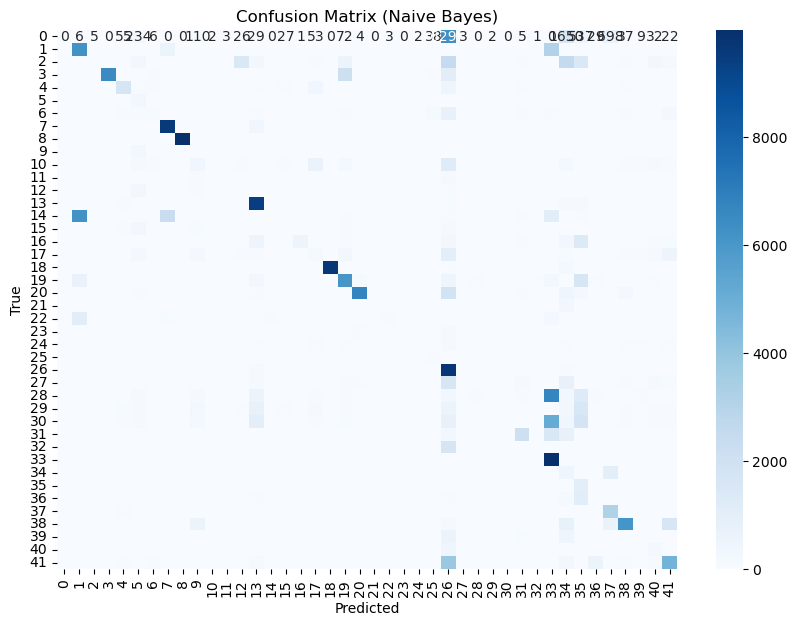


🔹 Training Decision Tree...
Decision Tree Performance:
  Accuracy:  0.7832
  Precision: 0.7842
  Recall:    0.7832
  F1-score:  0.7660


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize


Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.84      0.88     10000
           1       1.00      1.00      1.00     10000
           2       0.36      0.86      0.51     10000
           3       1.00      0.97      0.98     10000
           4       0.95      0.51      0.66      3064
           5       0.21      0.20      0.20       503
           6       0.62      0.61      0.61      1900
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       0.24      0.01      0.02       504
          10       0.34      0.35      0.34      3425
          11       0.00      0.00      0.00       339
          12       0.25      0.10      0.14       693
          13       1.00      0.93      0.96     10000
          14       1.00      0.97      0.98     10000
          15       0.31      0.07      0.12       969
          16       0.82      0.64      0.72      3452
  

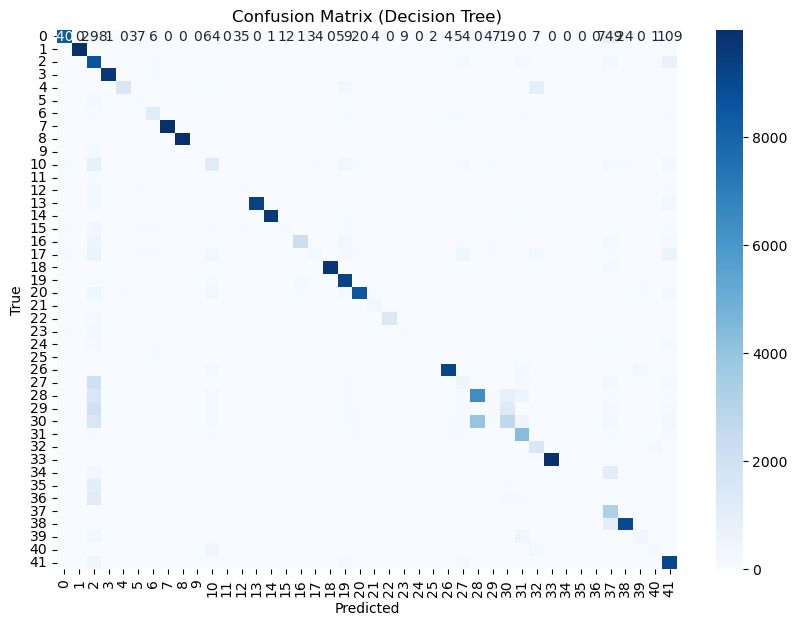


🔹 Training Gradient Boosting...
Gradient Boosting Performance:
  Accuracy:  0.0778
  Precision: 0.2212
  Recall:    0.0778
  F1-score:  0.0907

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.58      0.73     10000
           1       0.31      0.02      0.04     10000
           2       0.00      0.00      0.00     10000
           3       0.02      0.00      0.00     10000
           4       0.00      0.00      0.00      3064
           5       0.00      0.00      0.00       503
           6       0.00      0.09      0.01      1900
           7       0.00      0.00      0.00     10000
           8       0.00      0.00      0.00     10000
           9       0.00      0.07      0.00       504
          10       0.06      0.30      0.10      3425
          11       0.00      0.00      0.00       339
          12       0.00      0.00      0.00       693
          13       0.36      0.12      0.18     10000
          14       0

C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

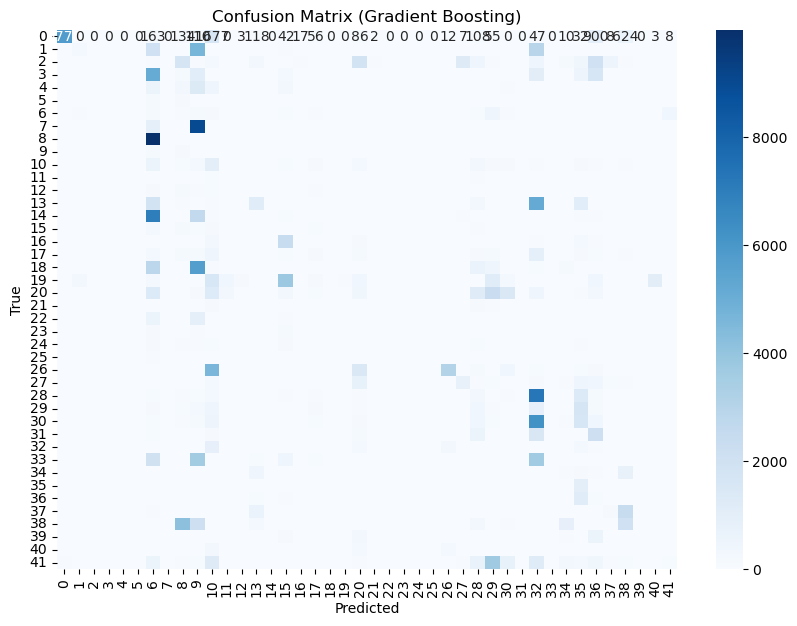


🔹 Training AdaBoost...
AdaBoost Performance:
  Accuracy:  0.2310
  Precision: 0.1145
  Recall:    0.2310
  F1-score:  0.1240

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00     10000
           1       0.13      0.99      0.23     10000
           2       0.26      0.64      0.36     10000
           3       0.39      0.32      0.35     10000
           4       0.00      0.00      0.00      3064
           5       0.00      0.00      0.00       503
           6       0.00      0.00      0.00      1900
           7       0.00      0.00      0.00     10000
           8       0.00      0.00      0.00     10000
           9       0.00      0.00      0.00       504
          10       0.00      0.00      0.00      3425
          11       0.00      0.00      0.00       339
          12       0.00      0.00      0.00       693
          13       0.37      0.73      0.49     10000
          14       0.00      0.00     

C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

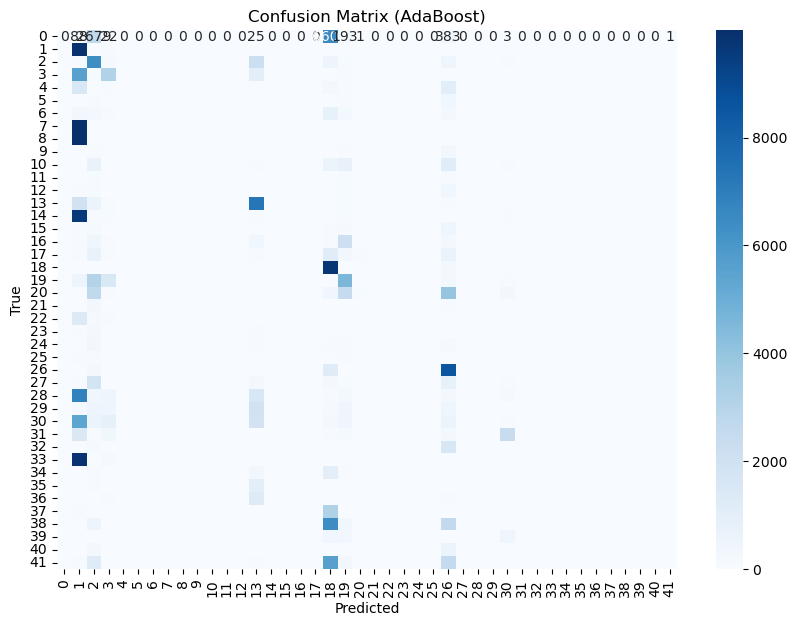


🔹 Training Extra Trees...
Extra Trees Performance:
  Accuracy:  0.8493
  Precision: 0.8493
  Recall:    0.8493
  F1-score:  0.8484

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.89      0.90     10000
           1       0.99      0.99      0.99     10000
           2       0.82      0.86      0.84     10000
           3       0.98      0.98      0.98     10000
           4       0.94      0.95      0.94      3064
           5       0.52      0.54      0.53       503
           6       0.78      0.84      0.81      1900
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       0.48      0.45      0.46       504
          10       0.60      0.65      0.62      3425
          11       0.33      0.24      0.28       339
          12       0.43      0.38      0.40       693
          13       0.99      0.98      0.98     10000
          14       0.99      0.9

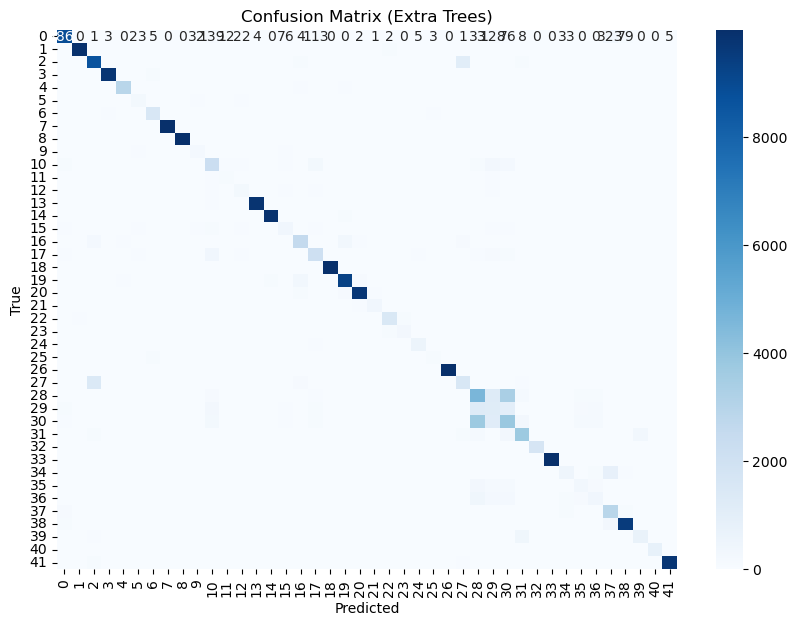


🔹 Training LightGBM...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM Performance:
  Accuracy:  0.4974
  Precision: 0.5149
  Recall:    0.4974
  F1-score:  0.4944

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.59      0.69     10000
           1       0.55      0.29      0.38     10000
           2       0.39      0.32      0.35     10000
           3       0.84      0.92      0.88     10000
           4       0.68      0.67      0.67      3064
           5       0.05      0.07      0.06       503
           6       0.03      0.01      0.02      1900
           7       0.90      0.85      0.88     10000
           8       0.88      0.91      0.89     10000
           9       0.01      0.01      0.01       504
          10       0.10      0.05      0.07      3425
          11       0.00      0.00      0.00       339
          12       0.00      0.00      0.00       693
          13       0.91      0.65      0.76     10000
          14       0.82      0.85      0.83     10000
        

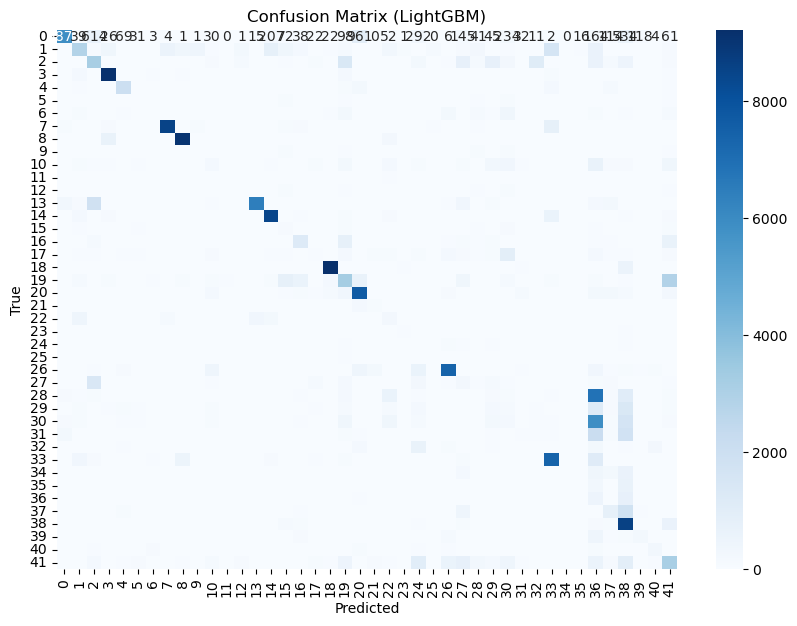


🔹 Training CatBoost...
CatBoost Performance:
  Accuracy:  0.8600
  Precision: 0.8672
  Recall:    0.8600
  F1-score:  0.8559

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.86      0.91     10000
           1       1.00      1.00      1.00     10000
           2       0.80      0.90      0.84     10000
           3       0.99      0.97      0.98     10000
           4       0.96      0.95      0.96      3064
           5       0.32      0.32      0.32       503
           6       0.70      0.81      0.75      1900
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       0.25      0.10      0.14       504
          10       0.39      0.77      0.52      3425
          11       1.00      0.02      0.04       339
          12       0.31      0.06      0.10       693
          13       1.00      0.98      0.99     10000
          14       1.00      0.99     

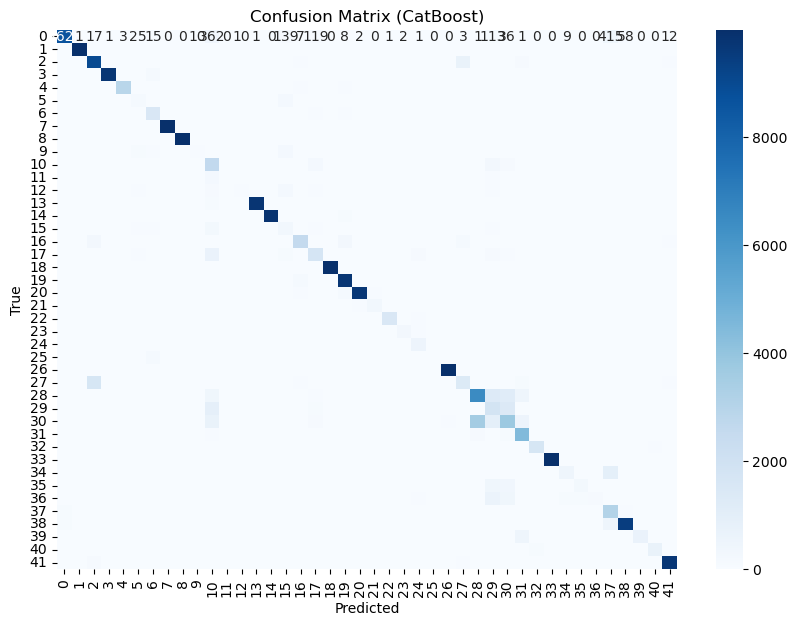


📊 Final Comparison:
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.791100   0.782641  0.791100  0.781105
Random Forest        0.852372   0.852818  0.852372  0.851676
XGBoost              0.875421   0.881357  0.875421  0.873631
KNN                  0.853682   0.852588  0.853682  0.851637
Naive Bayes          0.487776   0.465803  0.487776  0.434624
Decision Tree        0.783167   0.784227  0.783167  0.765994
Gradient Boosting    0.077769   0.221205  0.077769  0.090700
AdaBoost             0.231016   0.114472  0.231016  0.124010
Extra Trees          0.849279   0.849257  0.849279  0.848420
LightGBM             0.497408   0.514874  0.497408  0.494391
CatBoost             0.859970   0.867245  0.859970  0.855939


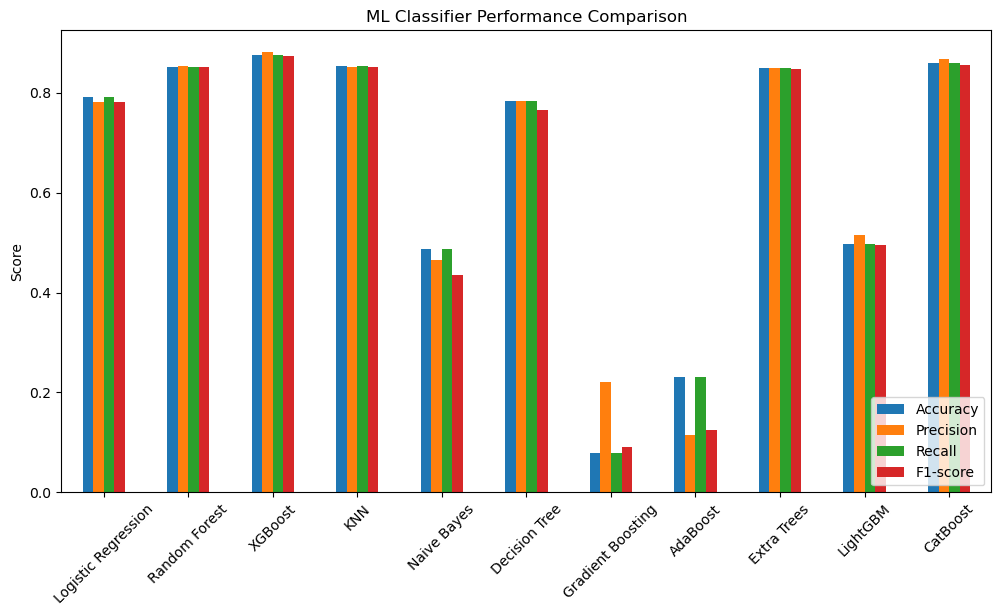

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature scaling (important for SVM, KNN, LR)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =====================================
# Define Models
# =====================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}

# =====================================
# Train & Evaluate
# =====================================
for name, model in models.items():
    print(f"\n🔹 Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

    print(f"{name} Performance:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=encoder.classes_.astype(str)))

    # Confusion Matrix
    class_names = encoder.classes_

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10,7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f"Confusion Matrix ({name})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.savefig(f"ML-Multi-Attack/Multiclass-ml-{name}.pdf")   # <-- save as PDF
    plt.show()


# =====================================
# Compare Results
# =====================================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison:\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack/Multi-ml-compare.pdf")   # <-- save as PDF
plt.show()


<h3>with k5-fold cross validation</h3>


🔹 Training Logistic Regression with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\

Logistic Regression Avg Performance:
  Accuracy:  0.7917
  Precision: 0.7830
  Recall:    0.7917
  F1-score:  0.7816

🔹 Training Random Forest with 5-Fold Cross Validation...
Random Forest Avg Performance:
  Accuracy:  0.8531
  Precision: 0.8532
  Recall:    0.8531
  F1-score:  0.8523

🔹 Training XGBoost with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [08:53:04] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [09:01:29] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [09:10:36] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [09:18:44] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:7

XGBoost Avg Performance:
  Accuracy:  0.8755
  Precision: 0.8818
  Recall:    0.8755
  F1-score:  0.8737

🔹 Training KNN with 5-Fold Cross Validation...
KNN Avg Performance:
  Accuracy:  0.8555
  Precision: 0.8545
  Recall:    0.8555
  F1-score:  0.8530

🔹 Training Naive Bayes with 5-Fold Cross Validation...
Naive Bayes Avg Performance:
  Accuracy:  0.5017
  Precision: 0.4716
  Recall:    0.5017
  F1-score:  0.4435

🔹 Training Decision Tree with 5-Fold Cross Validation...
Decision Tree Avg Performance:
  Accuracy:  0.7832
  Precision: 0.7877
  Recall:    0.7832
  F1-score:  0.7660

🔹 Training AdaBoost with 5-Fold Cross Validation...
AdaBoost Avg Performance:
  Accuracy:  0.2501
  Precision: 0.1405
  Recall:    0.2501
  F1-score:  0.1522

🔹 Training Extra Trees with 5-Fold Cross Validation...
Extra Trees Avg Performance:
  Accuracy:  0.8496
  Precision: 0.8493
  Recall:    0.8496
  F1-score:  0.8486

🔹 Training LightGBM with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMCla

LightGBM Avg Performance:
  Accuracy:  0.2829
  Precision: 0.3714
  Recall:    0.2829
  F1-score:  0.2735

🔹 Training CatBoost with 5-Fold Cross Validation...
CatBoost Avg Performance:
  Accuracy:  0.8611
  Precision: 0.8682
  Recall:    0.8611
  F1-score:  0.8569

📊 Final Comparison (5-Fold CV):
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.791700   0.783049  0.791700  0.781645
Random Forest        0.853117   0.853182  0.853117  0.852257
XGBoost              0.875486   0.881848  0.875486  0.873698
KNN                  0.855489   0.854493  0.855489  0.853046
Naive Bayes          0.501671   0.471611  0.501671  0.443548
Decision Tree        0.783221   0.787707  0.783221  0.766022
AdaBoost             0.250148   0.140538  0.250148  0.152189
Extra Trees          0.849638   0.849323  0.849638  0.848641
LightGBM             0.282876   0.371373  0.282876  0.273547
CatBoost             0.861143   0.868197  0.861143  0.856937


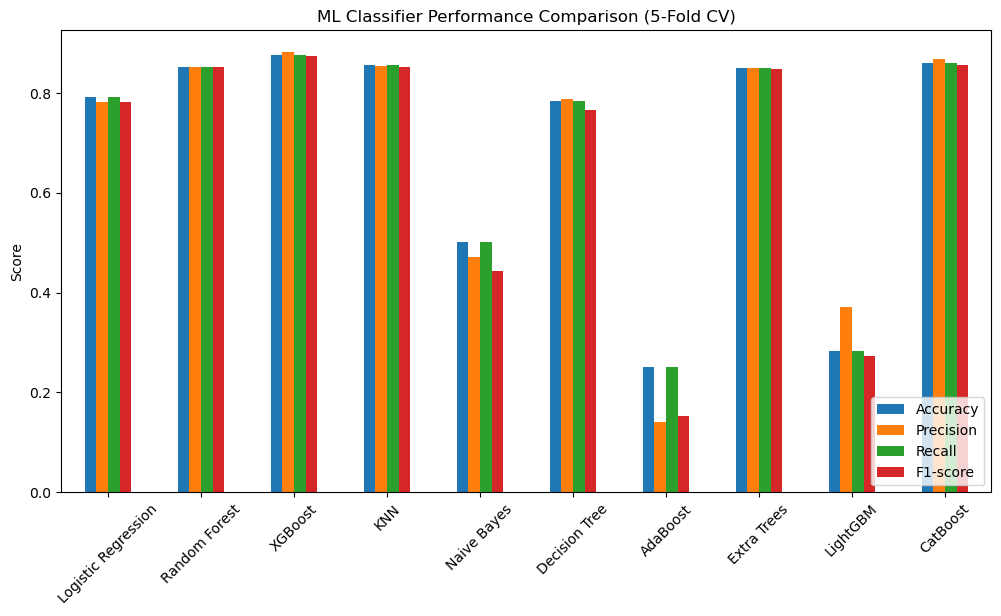

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# =============================
# Encode labels
# =============================
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# =============================
# Define Models
# =============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# =============================
# Train & Cross-Validate
# =============================
for name, model in models.items():
    print(f"\n🔹 Training {name} with 5-Fold Cross Validation...")

    acc_scores, prec_scores, rec_scores, f1_scores = [], [], [], []

    fold = 1
    for train_idx, test_idx in kf.split(X, y_encoded):
        # Use iloc to index rows correctly
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

        # Feature scaling
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        # Train & predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)


        # Metrics
        acc_scores.append(accuracy_score(y_test, y_pred))
        prec_scores.append(precision_score(y_test, y_pred, average="weighted", zero_division=0))
        rec_scores.append(recall_score(y_test, y_pred, average="weighted", zero_division=0))
        f1_scores.append(f1_score(y_test, y_pred, average="weighted", zero_division=0))

        # Save one confusion matrix per fold (optional)
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=encoder.classes_,
                    yticklabels=encoder.classes_)
        plt.title(f"{name} - Confusion Matrix (Fold {fold})")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.savefig(f"ML-Multi-Attack/Multi-ml-{name}-fold{fold}.pdf")
        plt.close()
        fold += 1

    # Average results
    results[name] = {
        "Accuracy": np.mean(acc_scores),
        "Precision": np.mean(prec_scores),
        "Recall": np.mean(rec_scores),
        "F1-score": np.mean(f1_scores)
    }

    print(f"{name} Avg Performance:")
    print(f"  Accuracy:  {np.mean(acc_scores):.4f}")
    print(f"  Precision: {np.mean(prec_scores):.4f}")
    print(f"  Recall:    {np.mean(rec_scores):.4f}")
    print(f"  F1-score:  {np.mean(f1_scores):.4f}")

# =============================
# Compare Results
# =============================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison (5-Fold CV):\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison (5-Fold CV)")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack/Multi-ml-compare-5fold.pdf")
plt.show()
